# TCN · Validation motorlarında pencere hatası
**Run All / Tümünü Çalıştır** ile seçicileri etkinleştirin. Başlangıç seçimi Motor 5, Uçuş 1’dir. Motor değişince o motorun ilk uçuşu seçilir. Bir fold için birden fazla tahmin dosyası varsa zaman damgasına göre en son dosya kullanılır.

**İşaretli hata = tahmin edilen RUL − gerçek RUL** (uçuş döngüsü). Renkler gerçek RUL’u gösterir. Pearson tablosunun uçuş içi sütunları, her pencereden kendi uçuş ortalaması çıkarılarak hesaplanır. İlişkiler nedensellik kanıtı değildir.

## WINDOW 256 STRIDE 1024

Aşağıdaki pencere analizleri eski stride=1024 deneylerini kullanır. Yeni [stride=256 epoch/RMSE grafikleri](#stride256-rmse) notebook sonundadır.

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown, clear_output

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "n_cmapss/processed/window_excel").is_dir())
base = root / "n_cmapss"
import json
from functools import lru_cache
import ipywidgets as widgets

splits = json.loads((base / "processed/split_folds.json").read_text())
folds = {unit: f["fold"] for f in splits["folds"] for unit in f["validation_units"]}

@lru_cache(maxsize=6)
def load_motor(unit):
    fold = folds[unit]
    xlsx = base / f"processed/window_excel/unit_{unit}_windows.xlsx"
    paths = sorted((base / "outputs/tcn/window_256_stride_1024").glob(f"fold_{fold}_*/predictions.csv"))
    if not paths:
        raise FileNotFoundError(f"Fold {fold}: predictions.csv bulunamadı.")
    path = paths[-1]
    pred = pd.read_csv(path)
    # Proje dışa aktarımının inline metin başlıklı, sayısal özet sayfasını oku.
    # Sadece ilgili XML üyesi açılır; büyük Window_Data sayfası belleğe alınmaz.
    with ZipFile(xlsx) as z:
        workbook = ET.fromstring(z.read("xl/workbook.xml"))
        sheet = next(s for s in workbook.findall(".//{*}sheet")
                     if s.get("name") == "Window_Summary")
        rel_id = sheet.attrib["{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id"]
        rels = ET.fromstring(z.read("xl/_rels/workbook.xml.rels"))
        target = next(r.get("Target") for r in rels if r.get("Id") == rel_id)
        member = target.lstrip("/") if target.startswith("/") else "xl/" + target
        rows = ET.fromstring(z.read(member)).findall(".//{*}sheetData/{*}row")
    headers = [c.findtext(".//{*}t") for c in rows[0]]
    summary = pd.DataFrame([[c.findtext("{*}v") for c in row] for row in rows[1:]],
                           columns=headers).apply(pd.to_numeric)
    data = summary.merge(pred, on="window_id", how="outer", suffixes=("", "_pred"),
                         validate="one_to_one", indicator=True)
    assert data["_merge"].eq("both").all()
    assert (data.unit.eq(unit) & data.unit_pred.eq(unit) & data.cycle.eq(data.cycle_pred)
            & data.rul.eq(data.actual_rul)).all()
    features = [name[:-5] for name in summary if name.endswith("_mean")]
    columns = [f"{f}_{s}" for f in features for s in ("mean", "std")]
    assert len(features) == 18 and np.isfinite(data[columns + ["actual_rul", "predicted_rul"]]).all().all()
    data = data.sort_values(["cycle", "start_row"]).reset_index(drop=True)
    data["error"] = data.predicted_rul - data.actual_rul
    flights = data.groupby("cycle")
    assert flights.actual_rul.nunique().eq(1).all()
    return data, features, columns, path.parent.name


In [2]:
def show_figure(fig):
    with BytesIO() as buf:
        fig.savefig(buf, format="png", dpi=125, bbox_inches="tight")
        display(Image(data=buf.getvalue()))
    plt.close(fig)

fields = ["alt_mean", "Mach_mean", "alt_std"]
labels = ["Ortalama irtifa (ft)", "Ortalama Mach", "İrtifa standart sapması (ft)"]

def render_motor(unit):
    data, features, columns, run = load_motor(unit)
    flights = data.groupby("cycle")
    print(f"Motor {unit} · Fold {folds[unit]} · {len(data)} pencere · {flights.ngroups} uçuş · {run}")
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, constrained_layout=True)
    for ax, field, label in zip(axes, fields, labels):
        points = ax.scatter(data[field], data.error, c=data.actual_rul, cmap="viridis",
                            s=15, alpha=0.75, linewidths=0)
        ax.axhline(0, color="#505050", lw=0.8)
        ax.set_xlabel(label)
    axes[0].set_ylabel("Tahmin − gerçek RUL (döngü)")
    fig.colorbar(points, ax=axes, label="Gerçek RUL (döngü)")
    fig.suptitle(f"Motor {unit} | Tüm pencerelerde çalışma koşulları ve hata")
    show_figure(fig)

def render_flight(unit, selected_cycle):
    data = load_motor(unit)[0]
    flights = data.groupby("cycle")
    flight = flights.get_group(selected_cycle)
    spread = flights.error.agg(["min", "max", "mean"])
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    a.plot(flight.start_row - flight.start_row.iloc[0], flight.error, "o-", lw=1)
    for wid in [854, 859]:
        point = flight.loc[flight.window_id == wid]
        if len(point):
            r = point.iloc[0]
            a.annotate(str(wid), (r.start_row-flight.start_row.iloc[0], r.error),
                       xytext=(3, 6), textcoords="offset points")
    a.set(title=f"Uçuş {selected_cycle} | Gerçek RUL {flight.actual_rul.iloc[0]:g}",
          xlabel="İlk pencereye göre başlangıç satırı", ylabel="Tahmin hatası (döngü)")
    b.vlines(spread.index, spread["min"], spread["max"], color="#779caa", label="Min–maks")
    b.scatter(spread.index, spread["mean"], s=9, color="#263e52", label="Ortalama")
    b.set(title="Aynı uçuşun pencereleri arasındaki hata aralığı",
          xlabel="Uçuş numarası", ylabel="Tahmin hatası (döngü)")
    b.legend()
    for ax in (a,b):
        ax.axhline(0, color="#555555", lw=0.8)
    show_figure(fig)
    display(flight[["window_id", "actual_rul", "predicted_rul", "error", *fields]].round(3))

def render_correlations(unit):
    data, features, columns, _ = load_motor(unit)
    flights = data.groupby("cycle")
    values = data[columns + ["error"]]
    within = values - flights[columns + ["error"]].transform("mean")
    def correlations(frame):
        return frame[columns].corrwith(frame["error"])

    overall_r = correlations(values)
    within_r = correlations(within)
    table = pd.DataFrame(index=pd.Index(features, name="Özellik"))
    for stat, label in [("mean", "Ortalama"), ("std", "Std")]:
        keys = [f"{f}_{stat}" for f in features]
        table[f"{label} · genel r"] = overall_r.loc[keys].to_numpy()
        table[f"{label} · uçuş içi r"] = within_r.loc[keys].to_numpy()
    display(table.style.format("{:+.3f}", na_rep="Tanımsız"))

In [3]:
def refresh(panel, function, *args):
    with panel:
        clear_output(wait=True)
        function(*args)

def change_cycle(change):
    refresh(flight_panel, render_flight, motor.value, change["new"])

def change_motor(change=None):
    unit = motor.value
    cycles = sorted(load_motor(unit)[0].cycle.unique().tolist())
    cycle.unobserve(change_cycle, names="value")
    try:
        cycle.options = cycles
        cycle.value = cycles[0]
    finally:
        cycle.observe(change_cycle, names="value")
    refresh(motor_panel, render_motor, unit)
    refresh(flight_panel, render_flight, unit, cycle.value)
    refresh(corr_panel, render_correlations, unit)

# Hücre tekrar çalıştırıldığında yeni kontrollere birer gözlemci bağlanır.
motor = widgets.Dropdown(options=[2, 5, 10, 16, 18, 20], value=5, description="Motor")
cycle = widgets.Dropdown(options=[1], value=1, description="Uçuş")
motor_panel, flight_panel, corr_panel = (widgets.Output() for _ in range(3))
cycle.observe(change_cycle, names="value")
motor.observe(change_motor, names="value")
display(widgets.HBox([motor, cycle]))
display(motor_panel)
display(Markdown("### Seçilen uçuşun pencereleri ve motorun uçuşlarına göre hata aralığı"))
display(flight_panel)
display(Markdown("### Pencere ortalamaları ve standart sapmalar için Pearson korelasyonları"))
display(corr_panel)
change_motor()




Motor 5 · Fold 2 · 1034 pencere · 89 uçuş · fold_2_20261120_104041_191049





,Ortalama · genel r,Ortalama · uçuş içi r,Std · genel r,Std · uçuş içi r
Özellik,,,,
alt,+0.400,+0.716,-0.272,-0.480
Mach,+0.379,+0.698,-0.300,-0.532
TRA,+0.155,+0.258,-0.008,-0.061
T2,-0.392,-0.698,-0.172,-0.307
T24,-0.316,-0.554,-0.049,-0.137
T30,-0.203,-0.325,-0.031,-0.099
T48,-0.063,-0.183,-0.023,-0.089
T50,-0.205,-0.461,-0.033,-0.107
P15,-0.399,-0.707,-0.178,-0.338


## Sabit örnek · Motor 5, Uçuş 1

Aşağıdaki iki ham zaman serisi, 854 ve 859 numaralı pencerelerin sabit karşılaştırmasıdır.

# Motor 5 · Uçuş 1 — Pencere 854 ve 859

İki grafik, aynı uçuşun farklı bölümlerindeki ham ölçümleri pencere başlangıcına göre hizalar. Her çizginin ortalaması ve popülasyon standart sapması (SS, ddof=0) kendi 256 adımından hesaplanır. Her iki pencerenin RUL etiketi 88 uçuş döngüsüdür.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from io import BytesIO

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "n_cmapss/preprocessing/data_loader.py").is_file())
sys.path.insert(0, str(root))
from n_cmapss.preprocessing.data_loader import (
    NCmapssDataLoader, load_feature_names,
)

ids = (854, 859)
names = load_feature_names()
# Sabit örnekler stride=1024 metadata kimliklerini kullanır.
import csv
from n_cmapss.preprocessing.create_windows import WindowRecord
with (root / "n_cmapss/processed/window_metadata.csv").open(newline="", encoding="utf-8") as file:
    records = [WindowRecord(window_id=int(r["window_id"]), unit=int(r["unit"]),
                            cycle=int(r["cycle"]), rul=float(r["rul"]),
                            start_row=int(r["start_row"]), end_row=int(r["end_row"]))
               for r in csv.DictReader(file) if int(r["window_id"]) in ids]
assert sorted(w.window_id for w in records) == list(ids)
series = {}
with NCmapssDataLoader() as loader:
    for w in records:
        assert (w.unit, w.cycle, w.rul, w.end_row - w.start_row) == (5, 1, 88, 256)
        features, _ = loader.load_window(w)
        series[w.window_id] = {
            name: features[:, names.index(name)].astype(np.float64)
            for name in ("alt", "Mach")
        }

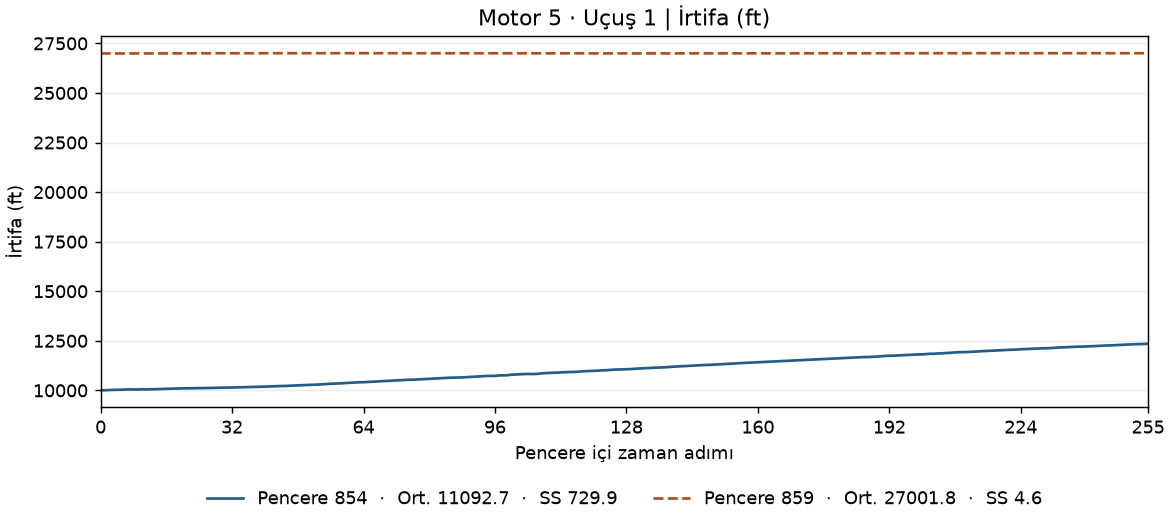

In [5]:
def compare_feature(name, ylabel, precision):
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for wid, color, style in zip(ids, ("#245C86", "#B14D20"), ("-", "--")):
        values = series[wid][name]
        label = (f"Pencere {wid}  ·  Ort. {values.mean():.{precision}f}"
                 f"  ·  SS {values.std(ddof=0):.{precision}f}")
        ax.plot(np.arange(256), values, color=color, linestyle=style, label=label)
    ax.set(xlim=(0, 255), xlabel="Pencere içi zaman adımı", ylabel=ylabel,
           title=f"Motor 5 · Uçuş 1 | {ylabel}")
    ax.set_xticks([0, 32, 64, 96, 128, 160, 192, 224, 255])
    ax.grid(axis="y", alpha=0.22)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, ncol=2)
    with BytesIO() as image:
        fig.savefig(image, format="png", dpi=130)
        display(Image(data=image.getvalue()))
    plt.close(fig)

compare_feature("alt", "İrtifa (ft)", 1)

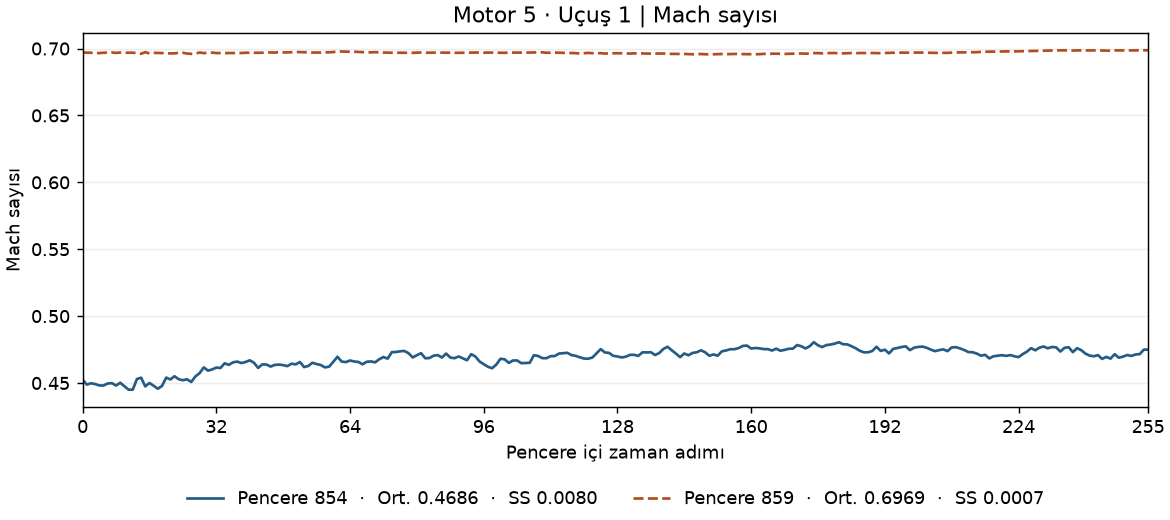

In [6]:
compare_feature("Mach", "Mach sayısı", 4)

<a id="stride256-rmse"></a>

# WINDOW 256 STRIDE 256

## Deney 1: Baseline Model — Epoch Boyunca Validation RMSE

`metrics.csv` yalnızca seçilen en iyi epoch’un RMSE özetini içerir. Epoch eğrileri `history.csv` dosyasındaki `validation_rmse` sütunundan çizilir; turuncu noktalar `metrics.csv` içindeki `best_epoch` ve `rmse` değerlerini gösterir. Her fold için baseline deney klasöründeki en son tamamlanmış kayıt kullanılır. Altı panel aynı eksen ölçeğini kullanır; erken durdurulan eğitimlerin eğrileri kendi son epoch’unda biter. RMSE birimi uçuş döngüsüdür.

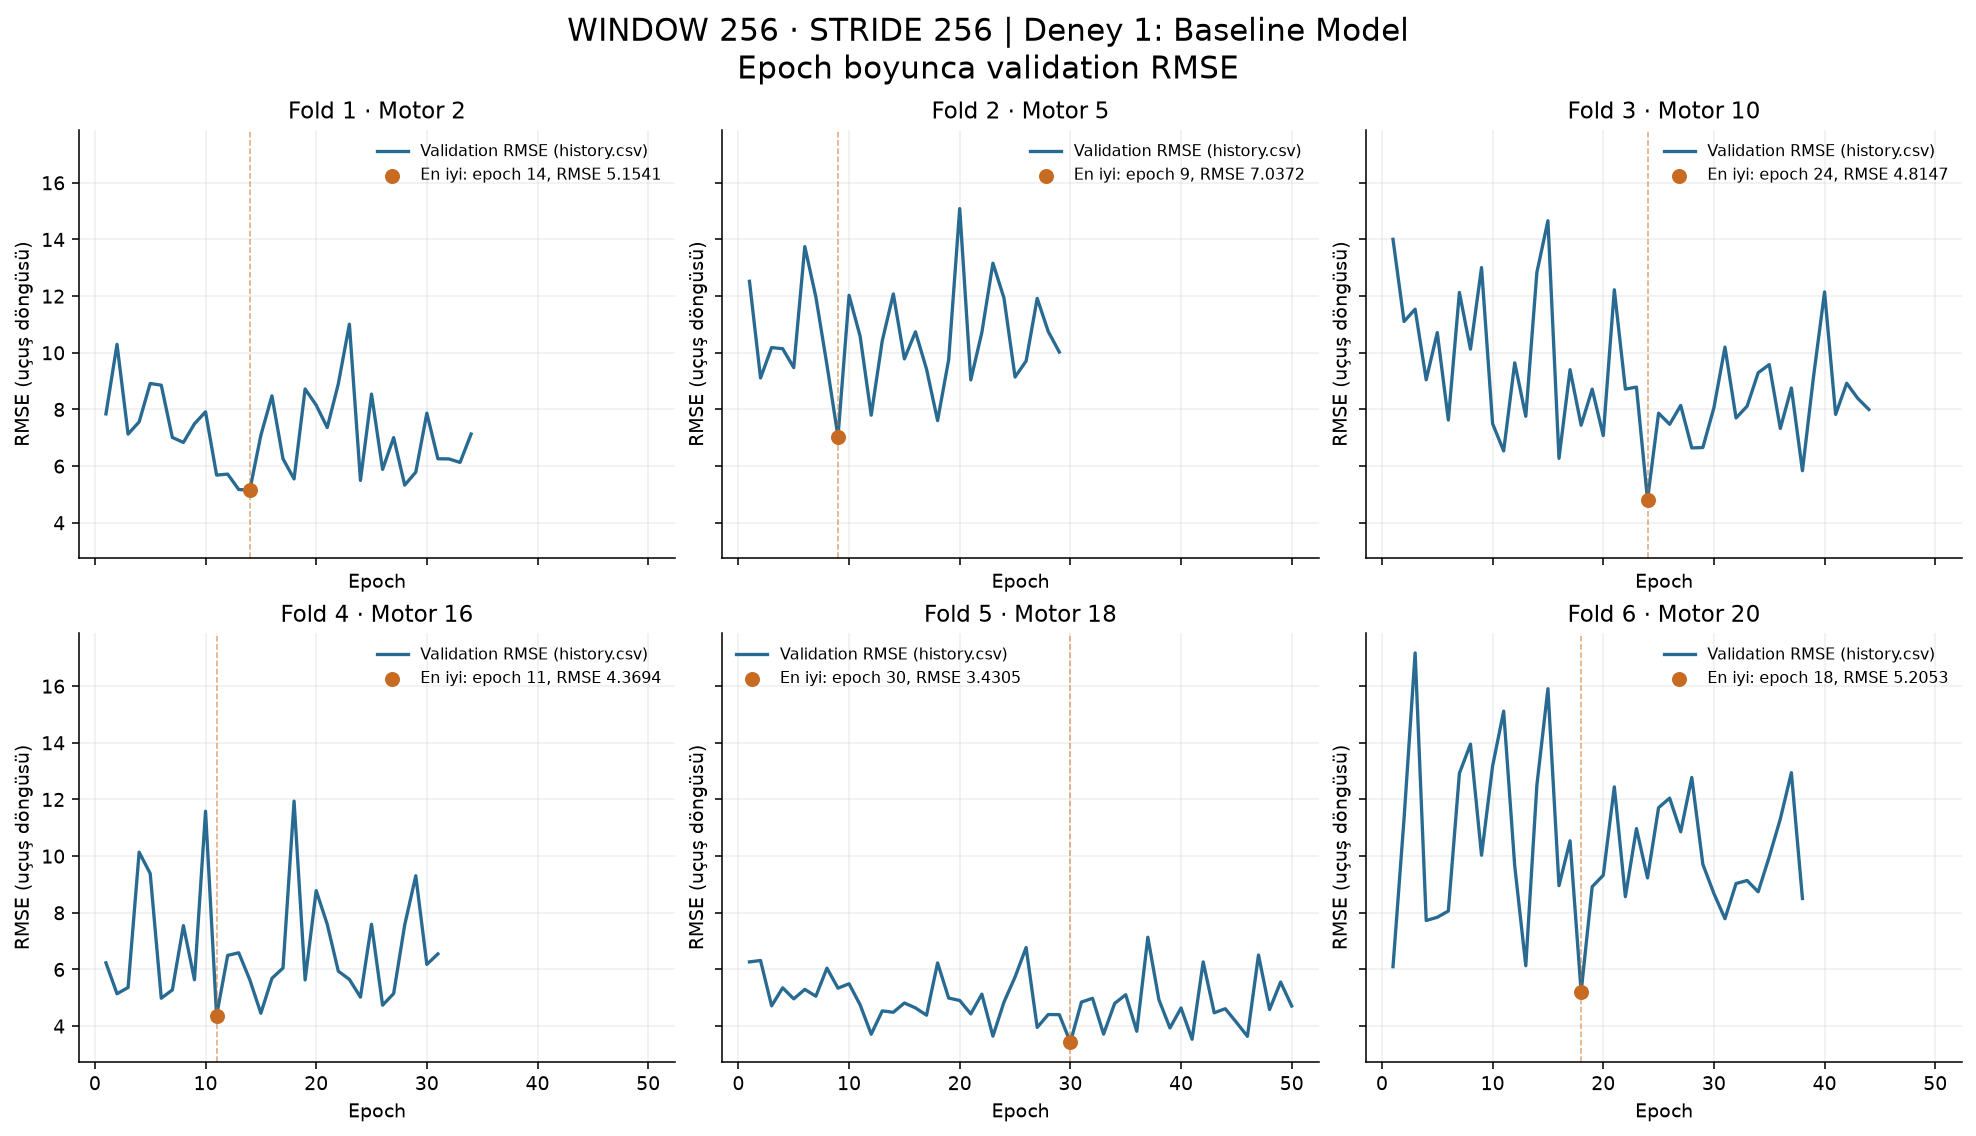

Fold,Motor,Epoch sayısı,En iyi epoch,Validation RMSE
1,2,34,14,5.1541
2,5,29,9,7.0372
3,10,44,24,4.8147
4,16,31,11,4.3694
5,18,50,30,3.4305
6,20,38,18,5.2053


In [7]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display


def plot_stride256_validation_rmse():
    base = next(p / 'n_cmapss' for p in (Path.cwd(), *Path.cwd().parents)
                if (p / 'n_cmapss/processed/window_256_stride_256/split_folds.json').is_file())
    folder = base / 'outputs/tcn/window_256_stride_256/seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001'
    splits = json.loads((base / 'processed/window_256_stride_256/split_folds.json').read_text())['folds']
    curves, rows = [], []
    for split in sorted(splits, key=lambda s: s['fold']):
        fold, unit = split['fold'], split['validation_units'][0]
        paths = sorted(p for p in folder.glob(f'fold_{fold}_*/metrics.csv')
                       if p.with_name('history.csv').is_file())
        if not paths:
            raise FileNotFoundError(f'Fold {fold}: metrics.csv / history.csv bulunamadı.')
        path = paths[-1]
        metric, = pd.read_csv(path).to_dict('records')
        history = pd.read_csv(path.with_name('history.csv')).sort_values('epoch')
        assert metric['fold'] == fold and metric['validation_unit'] == unit
        assert not history.empty and history.epoch.is_unique
        np.testing.assert_array_equal(history.epoch, np.arange(1, len(history) + 1))
        assert np.isfinite(history[['validation_rmse', 'validation_mse']]).all().all()
        assert history.validation_mse.ge(0).all()
        np.testing.assert_allclose(history.validation_rmse, np.sqrt(history.validation_mse), rtol=1e-10)
        best_epoch = int(metric['best_epoch'])
        best = history.loc[history.epoch == best_epoch].iloc[0]
        assert best_epoch == int(history.loc[history.validation_mse.idxmin(), 'epoch'])
        # metrics.csv tahminlerden, history.csv batch MSE'den hesaplandığı için
        # float32 toplama farklarına küçük bir tolerans verilir.
        np.testing.assert_allclose(best.validation_rmse, metric['rmse'], rtol=1e-5)
        curves.append((fold, unit, history, best_epoch, metric['rmse']))
        rows.append({'Fold': fold, 'Motor': unit, 'Epoch sayısı': len(history),
                     'En iyi epoch': best_epoch, 'Validation RMSE': metric['rmse']})
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True,
                             constrained_layout=True)
    for ax, (fold, unit, history, best_epoch, best_rmse) in zip(axes.flat, curves, strict=True):
        ax.plot(history.epoch, history.validation_rmse, color='#286A91', linewidth=1.7,
                label='Validation RMSE (history.csv)')
        ax.scatter([best_epoch], [best_rmse], color='#C76B23', s=45, zorder=3,
                   label=f'En iyi: epoch {best_epoch}, RMSE {best_rmse:.4f}')
        ax.axvline(best_epoch, color='#C76B23', linestyle='--', linewidth=0.8, alpha=0.6)
        ax.set(title=f'Fold {fold} · Motor {unit}', xlabel='Epoch', ylabel='RMSE (uçuş döngüsü)')
        ax.grid(alpha=0.2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(fontsize=8, frameon=False)
    fig.suptitle('WINDOW 256 · STRIDE 256 | Deney 1: Baseline Model\nEpoch boyunca validation RMSE', fontsize=16)
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
        display(Image(data=buffer.getvalue()))
    plt.close(fig)
    return pd.DataFrame(rows)


stride256_rmse_summary = plot_stride256_validation_rmse()
display(stride256_rmse_summary.style.hide(axis='index').format({'Validation RMSE': '{:.4f}'}))
